# ***Визуализация данных / Data Visualization***

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
import seaborn as sns

# **Bar Chart — средний итоговый балл по программам / Average Final Score by Program**

In [ ]:
import pandas as pd
df_clean = pd.read_csv("University Students 2026 New.csv")

In [ ]:
average_score = (
    df_clean
    .groupby("program", as_index=False)["final_score"]
    .mean()
)

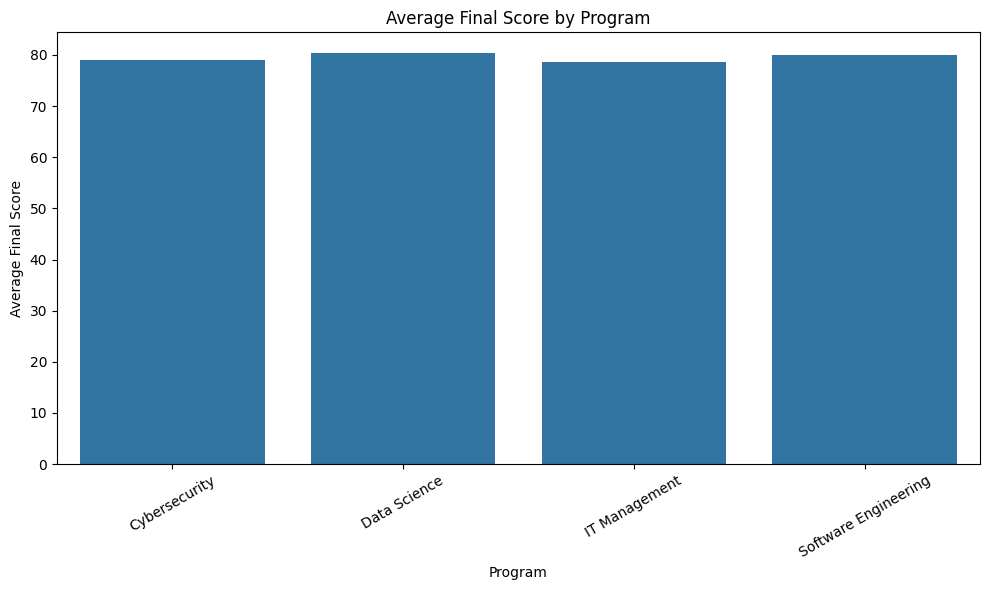

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=average_score,
    x="program",
    y="final_score"
)

plt.title("Average Final Score by Program")
plt.xlabel("Program")
plt.ylabel("Average Final Score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

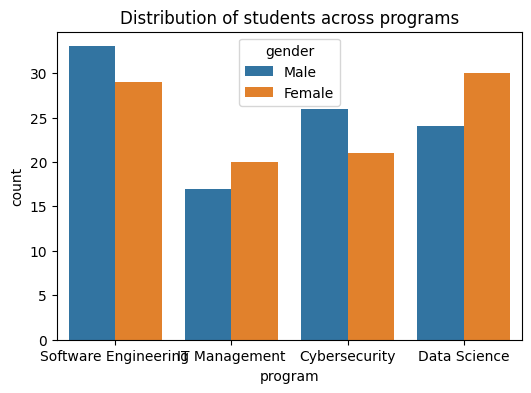

In [ ]:
# Countplot: частоты категорий
plt.figure(figsize=(6,4))
sns.countplot(data=df_clean, x="program", hue="gender")  # частоты по классам с разбиением по полу
plt.title("Distribution of students across programs")
plt.show()

# **Scatter Plot — посещаемость и итоговая оценка / Attendance vs Final Score**

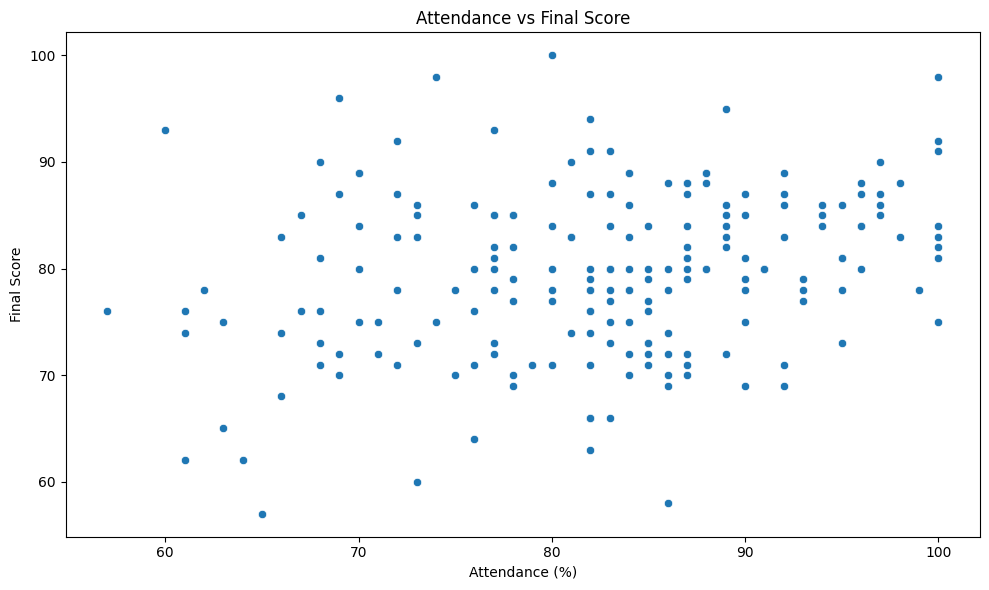

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="attendance",
    y="final_score"
)

plt.title("Attendance vs Final Score")
plt.xlabel("Attendance (%)")
plt.ylabel("Final Score")
plt.tight_layout()
plt.show()

# **Scatter Plot с линией регрессии / Scatter Plot with Regression Line**

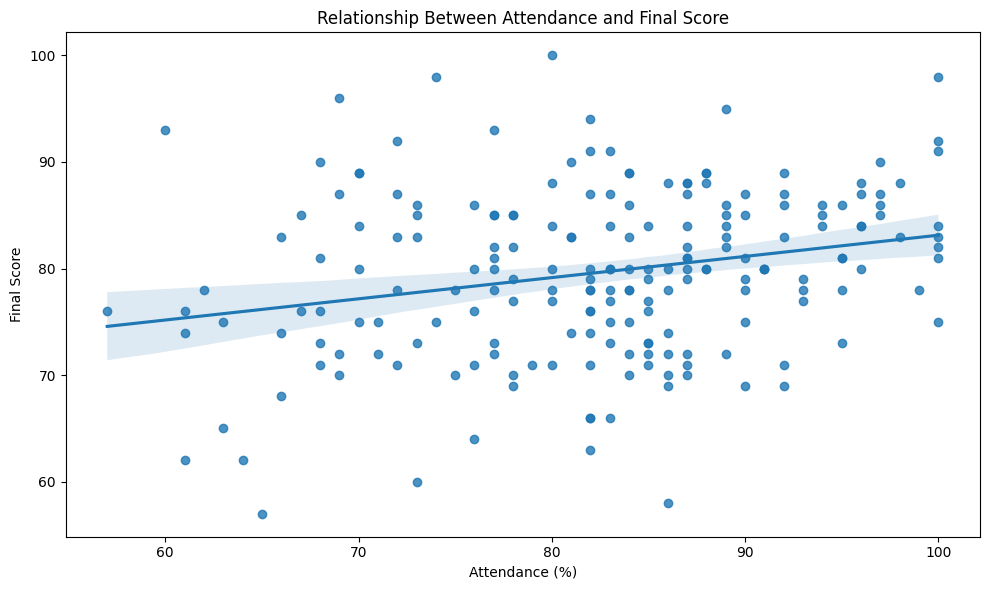

In [ ]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_clean,
    x="attendance",
    y="final_score"
)

plt.title("Relationship Between Attendance and Final Score")
plt.xlabel("Attendance (%)")
plt.ylabel("Final Score")
plt.tight_layout()
plt.show()

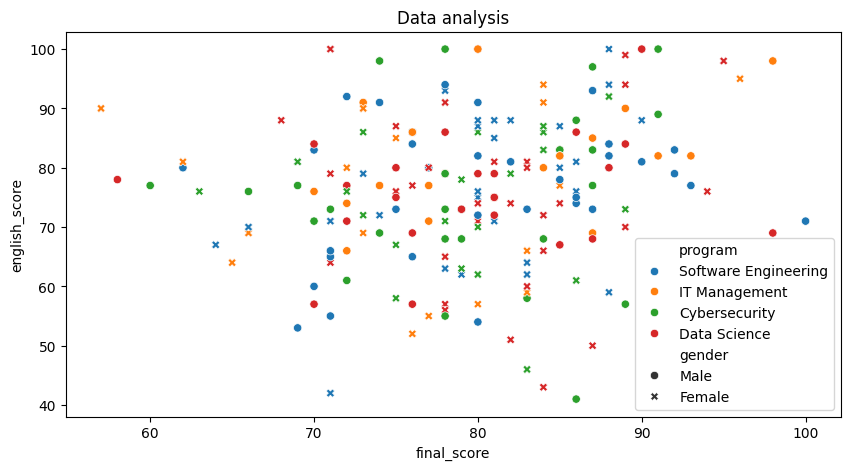

In [ ]:
plt.figure(figsize=(10,5))
sns.scatterplot(data=df_clean, x="final_score",
                y="english_score", hue="program", style="gender")
plt.title("Data analysis")
plt.show()

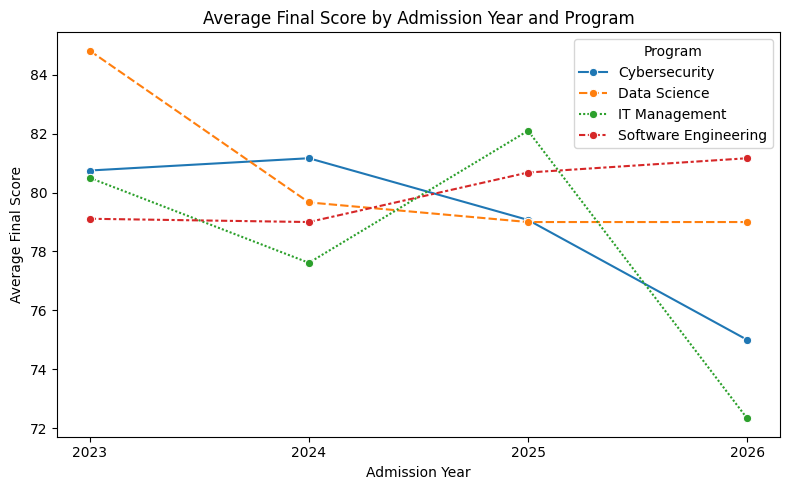

In [ ]:
df_clean["admission_date"] = pd.to_datetime(
    df_clean["admission_date"]
)
df_clean["admission_year"] = df_clean["admission_date"].dt.year

data_pivot = df_clean.pivot_table(
    index="admission_year",
    columns="program",
    values="final_score",
    aggfunc="mean"
)

plt.figure(figsize=(8, 5))
sns.lineplot(data=data_pivot, marker="o")

plt.title("Average Final Score by Admission Year and Program")
plt.xlabel("Admission Year")
plt.ylabel("Average Final Score")
plt.legend(title="Program")
plt.xticks(data_pivot.index)
plt.tight_layout()
plt.show()

# **Boxplot — распределение итоговых оценок по программам / Final Score Distribution by Program**

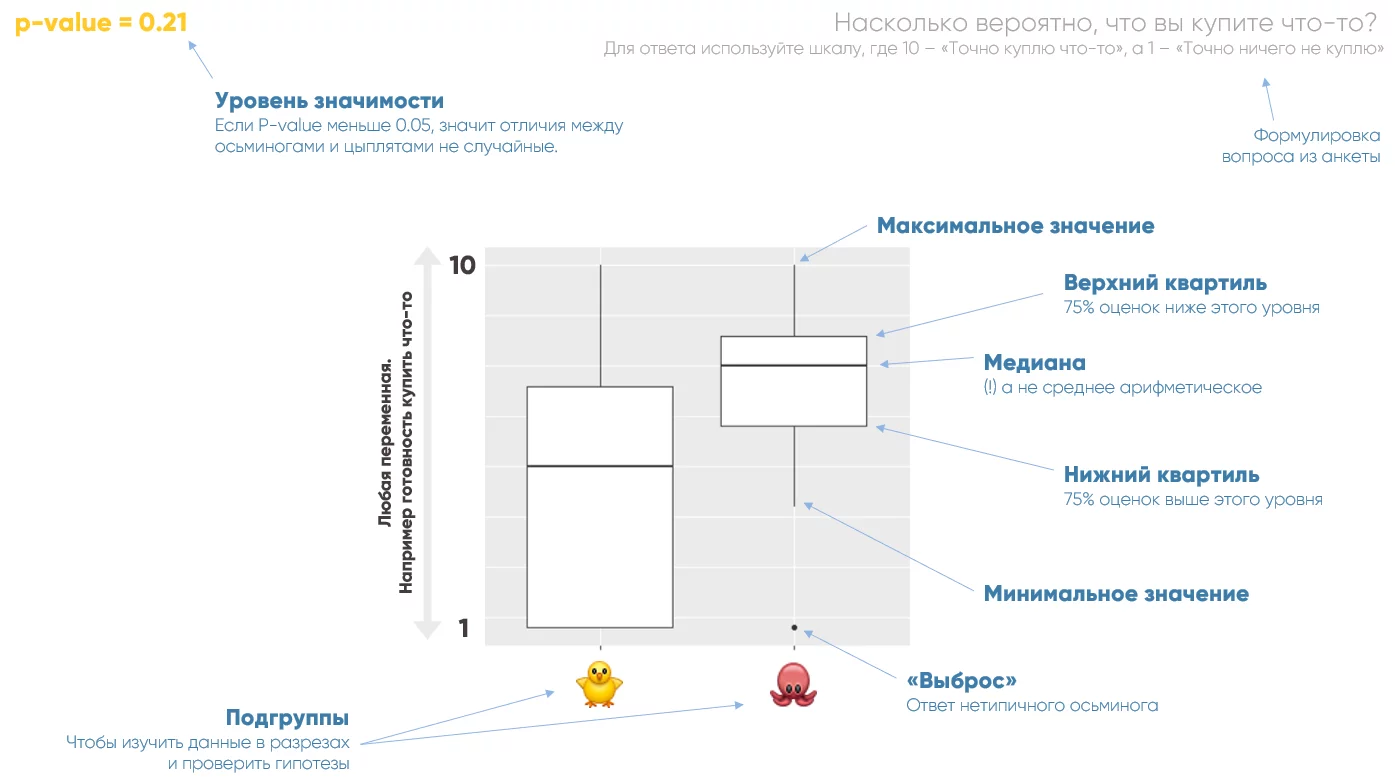

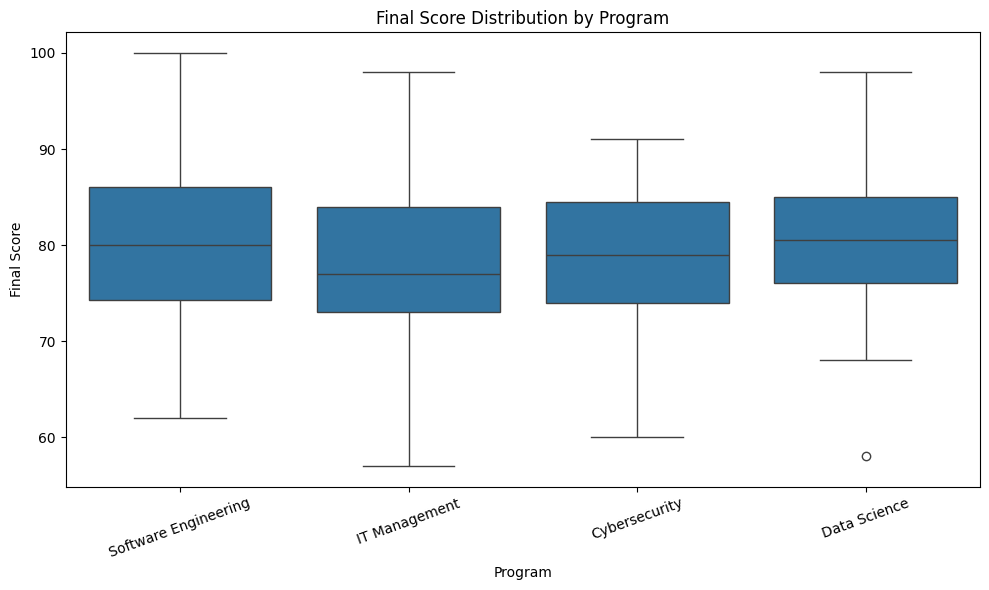

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x="program",
    y="final_score"
)

plt.title("Final Score Distribution by Program")
plt.xlabel("Program")
plt.ylabel("Final Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# **Box/Violin/Boxen/Swarm/Strip**

# **violinplot** показывает:
# распределение данных по признаку;
# плотность вероятности (kernel density estimation, KDE);
# медиану и квартили (как boxplot).
# То есть это комбинация boxplot + сглаженная кривая распределения (напоминает форму скрипки 🎻, отсюда название).

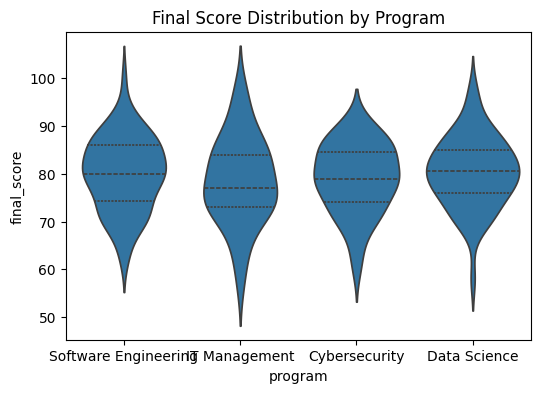

In [ ]:
# Violinplot: плотности по группам
plt.figure(figsize=(6,4))
sns.violinplot(data=df_clean, x="program", y="final_score", inner="quartile")
plt.title("Final Score Distribution by Program")
plt.show()

# **boxenplot** (или letter-value plot) — это расширенный вариант boxplot в библиотеке Seaborn, который тоже используется для визуализации распределений данных.
# 📌 Он показывает:
# медиану, квартили (как boxplot);
# выбросы;
# но главное — детализированные "хвосты" распределения: чем дальше от медианы, тем глубже строятся дополнительные уровни (letter-values).
# Таким образом, boxenplot полезен для:
# больших выборок;
# асимметричных распределений;
# анализа длинных хвостов данных.

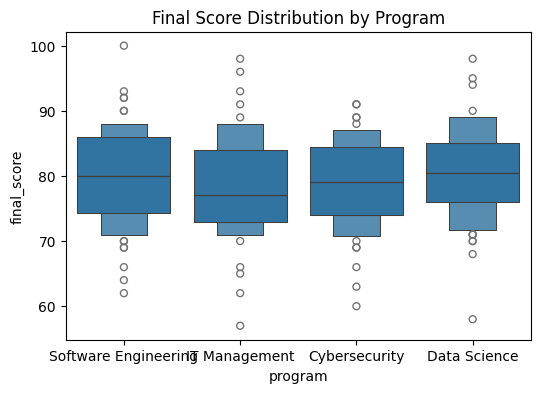

In [ ]:
# Boxenplot: устойчив к крупным выборкам
plt.figure(figsize=(6,4))
sns.boxenplot(data=df_clean, # .sample(200, random_state=0)
              x="program",
              y="final_score")
plt.title("Final Score Distribution by Program")
plt.show()

# **stripplot** располагает все наблюдения по категориям. jitter=True немного смещает точки по горизонтали, чтобы они меньше накладывались друг на друга.
# **stripplot** displays individual observations by category. jitter=True slightly shifts points horizontally to reduce overlap.

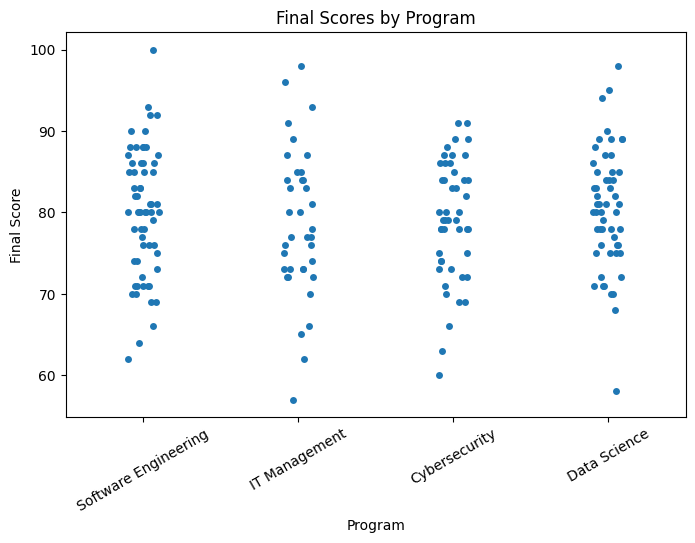

In [ ]:
plt.figure(figsize=(8, 5))

sns.stripplot(
    data=df_clean,
    x="program",
    y="final_score",
    jitter=True
)

plt.title("Final Scores by Program")
plt.xlabel("Program")
plt.ylabel("Final Score")
plt.xticks(rotation=30)
plt.show()

# **swarmplot **автоматически располагает точки так, чтобы они не перекрывали друг друга. Поэтому распределение видно лучше.
# **swarmplot** automatically arranges points so that they do not overlap, making the distribution easier to see.

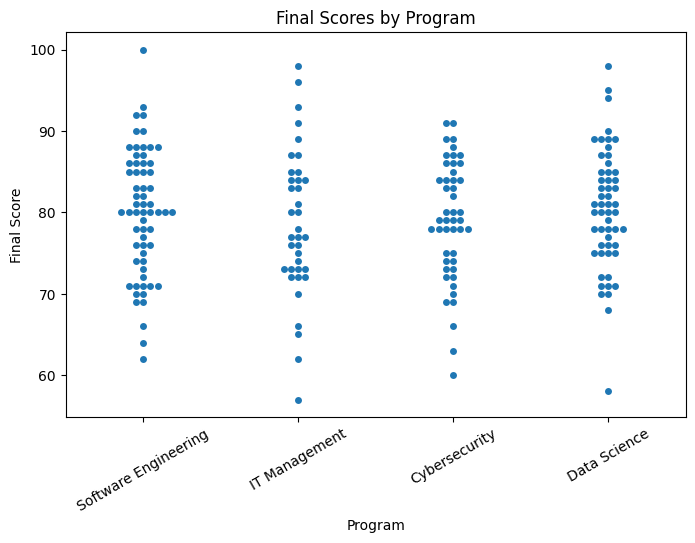

In [ ]:
plt.figure(figsize=(8, 5))

sns.swarmplot(
    data=df_clean,
    x="program",
    y="final_score"
)

plt.title("Final Scores by Program")
plt.xlabel("Program")
plt.ylabel("Final Score")
plt.xticks(rotation=30)
plt.show()

| | `stripplot` | `swarmplot` |
|---|---|---|
| Показывает отдельные наблюдения | Да | Да |
| Точки могут перекрываться | Да | Практически нет |
| Смещение точек | случайное `jitter` | рассчитывается автоматически |
| Большие датасеты | быстрее | может быть медленным |
| 200 студентов | отлично подходит | отлично подходит |

# **Histogram — распределение итоговых оценок / Final Score Distribution**

# A histogram divides values into intervals (bins) and shows how many observations fall into each interval.
# Гистограмма разбивает значения на интервалы (bins) и показывает, сколько наблюдений попало в каждый интервал.

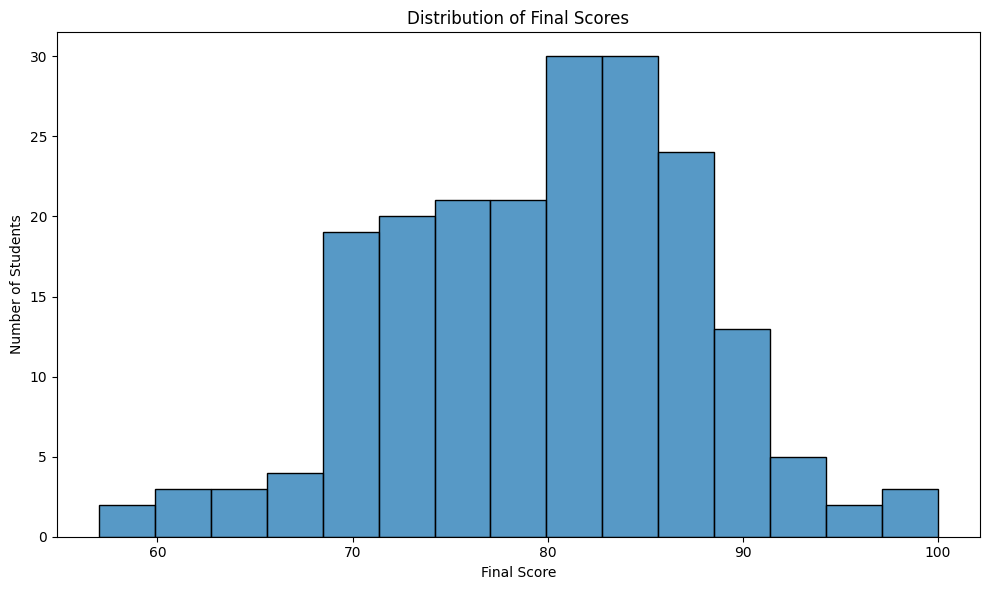

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x="final_score",
    bins=15
)

plt.title("Distribution of Final Scores")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

# **Heatmap корреляционной матрицы / Correlation Matrix Heatmap**

In [ ]:
numeric_columns = [
    "admission_score",
    "math_score",
    "programming_score",
    "english_score",
    "attendance",
    "assignments",
    "final_score"
]

correlation_matrix = df_clean[numeric_columns].corr()

correlation_matrix

,admission_score,math_score,programming_score,english_score,attendance,assignments,final_score
admission_score,1.000000,0.594307,0.187716,-0.054725,-0.064860,0.073125,0.306237
math_score,0.594307,1.000000,0.410717,-0.039936,0.065345,0.256679,0.590259
programming_score,0.187716,0.410717,1.000000,-0.106805,0.050985,0.567902,0.678177
english_score,-0.054725,-0.039936,-0.106805,1.000000,-0.015331,-0.068072,0.165048
attendance,-0.064860,0.065345,0.050985,-0.015331,1.000000,0.383287,0.248696
assignments,0.073125,0.256679,0.567902,-0.068072,0.383287,1.000000,0.618500
final_score,0.306237,0.590259,0.678177,0.165048,0.248696,0.618500,1.000000


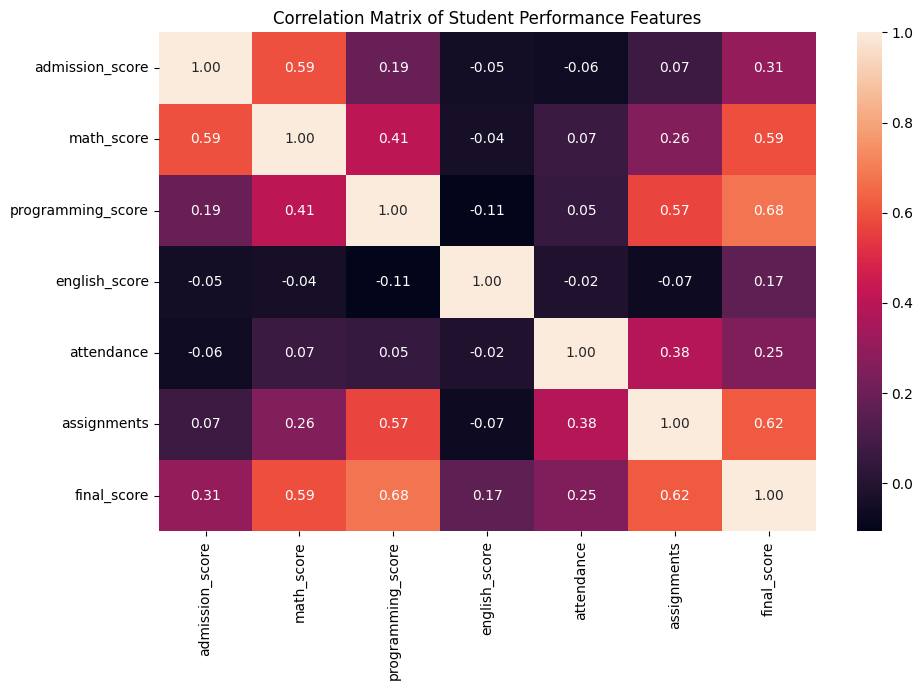

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix of Student Performance Features")
plt.tight_layout()
plt.show()

# Axes-level vs Figure-level
# Axes-level функции рисуют внутри переданной оси (например, sns.scatterplot, sns.histplot, sns.boxplot).
# Figure-level функции создают целую фигуру с FacetGrid (например, sns.relplot, sns.displot, sns.catplot, sns.lmplot), удобно для faceting.

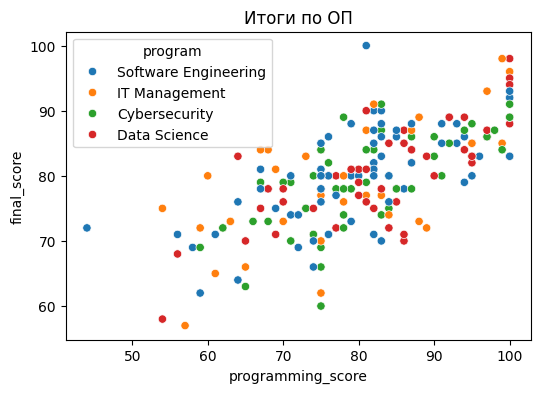

In [ ]:
# Axes-level
fig, ax = plt.subplots(figsize=(6,4))
sns.scatterplot(data=df_clean, x="programming_score", y="final_score", hue="program", ax=ax)  # рисуем в ax
ax.set_title("Итоги по ОП")
plt.show()

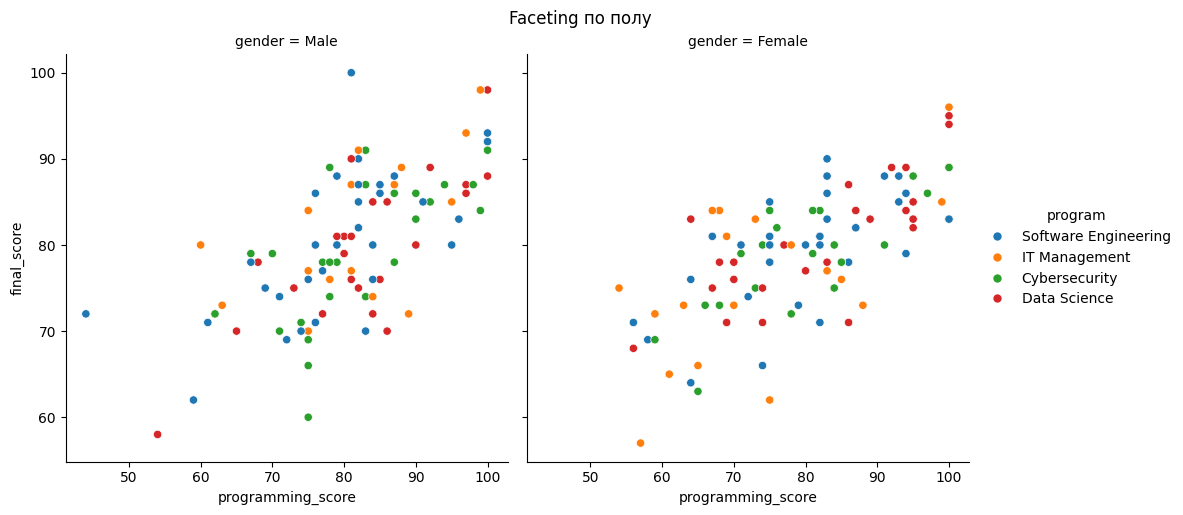

In [ ]:
# Figure-level пример (автоматически создает Figure+FacetGrid)
g = sns.relplot(data=df_clean, x="programming_score", y="final_score", hue="program", col="gender")
g.fig.suptitle("Faceting по полу", y=1.02)
plt.show()

# **Диаграммы распределений и плотности**

# **KDE (Kernel Density Estimation)** — это метод оценки распределения числовых данных с помощью гладкой кривой.
# Он позволяет увидеть, в каких диапазонах значений наблюдений много, а в каких — мало.
# Плотность вероятности (probability density) показывает, насколько сильно данные сконцентрированы около определённого значения.

# То есть:
# - высокий участок KDE-кривой → в этой области находится много наблюдений;
# - низкий участок → наблюдений мало;
# - несколько пиков → в данных может быть несколько групп.

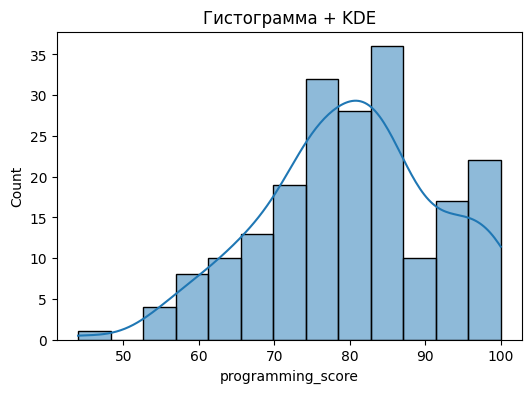

In [ ]:
# Гистограмма + оценка плотности KDE по длинне клюва
plt.figure(figsize=(6,4))
sns.histplot(data=df_clean, x="programming_score", kde=True)  # kde=True добавляет кривую плотности
plt.title("Гистограмма + KDE")
plt.show()

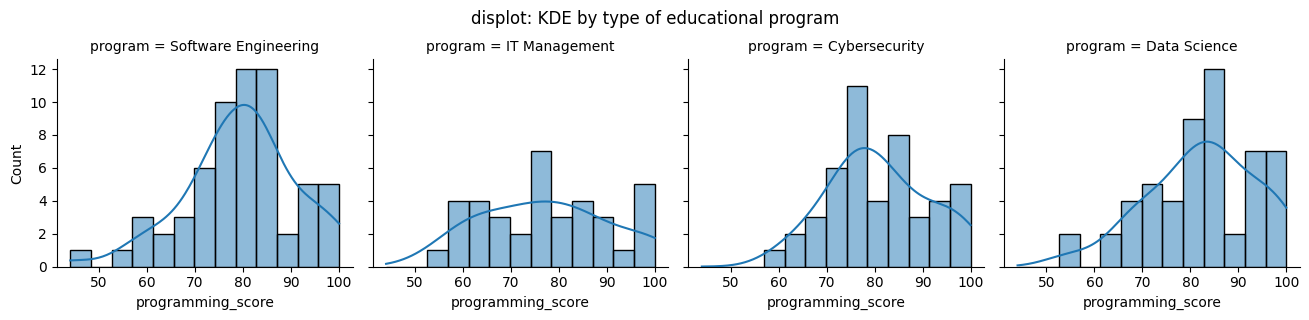

In [ ]:
# Figure-level
g = sns.displot(data=df_clean,
                x="programming_score",
                col="program",
                kde=True,
                height=3, aspect=1.1)
g.fig.suptitle("displot: KDE by type of educational program", y=1.05)
plt.show()

# height=3 задаёт высоту каждого графика — 3 дюйма.
# aspect=1.1 задаёт отношение ширины графика к его высоте.
# height=3 sets the height of each subplot to 3 inches.
# aspect=1.1 sets the width-to-height ratio of each subplot.

# **Pairplot**

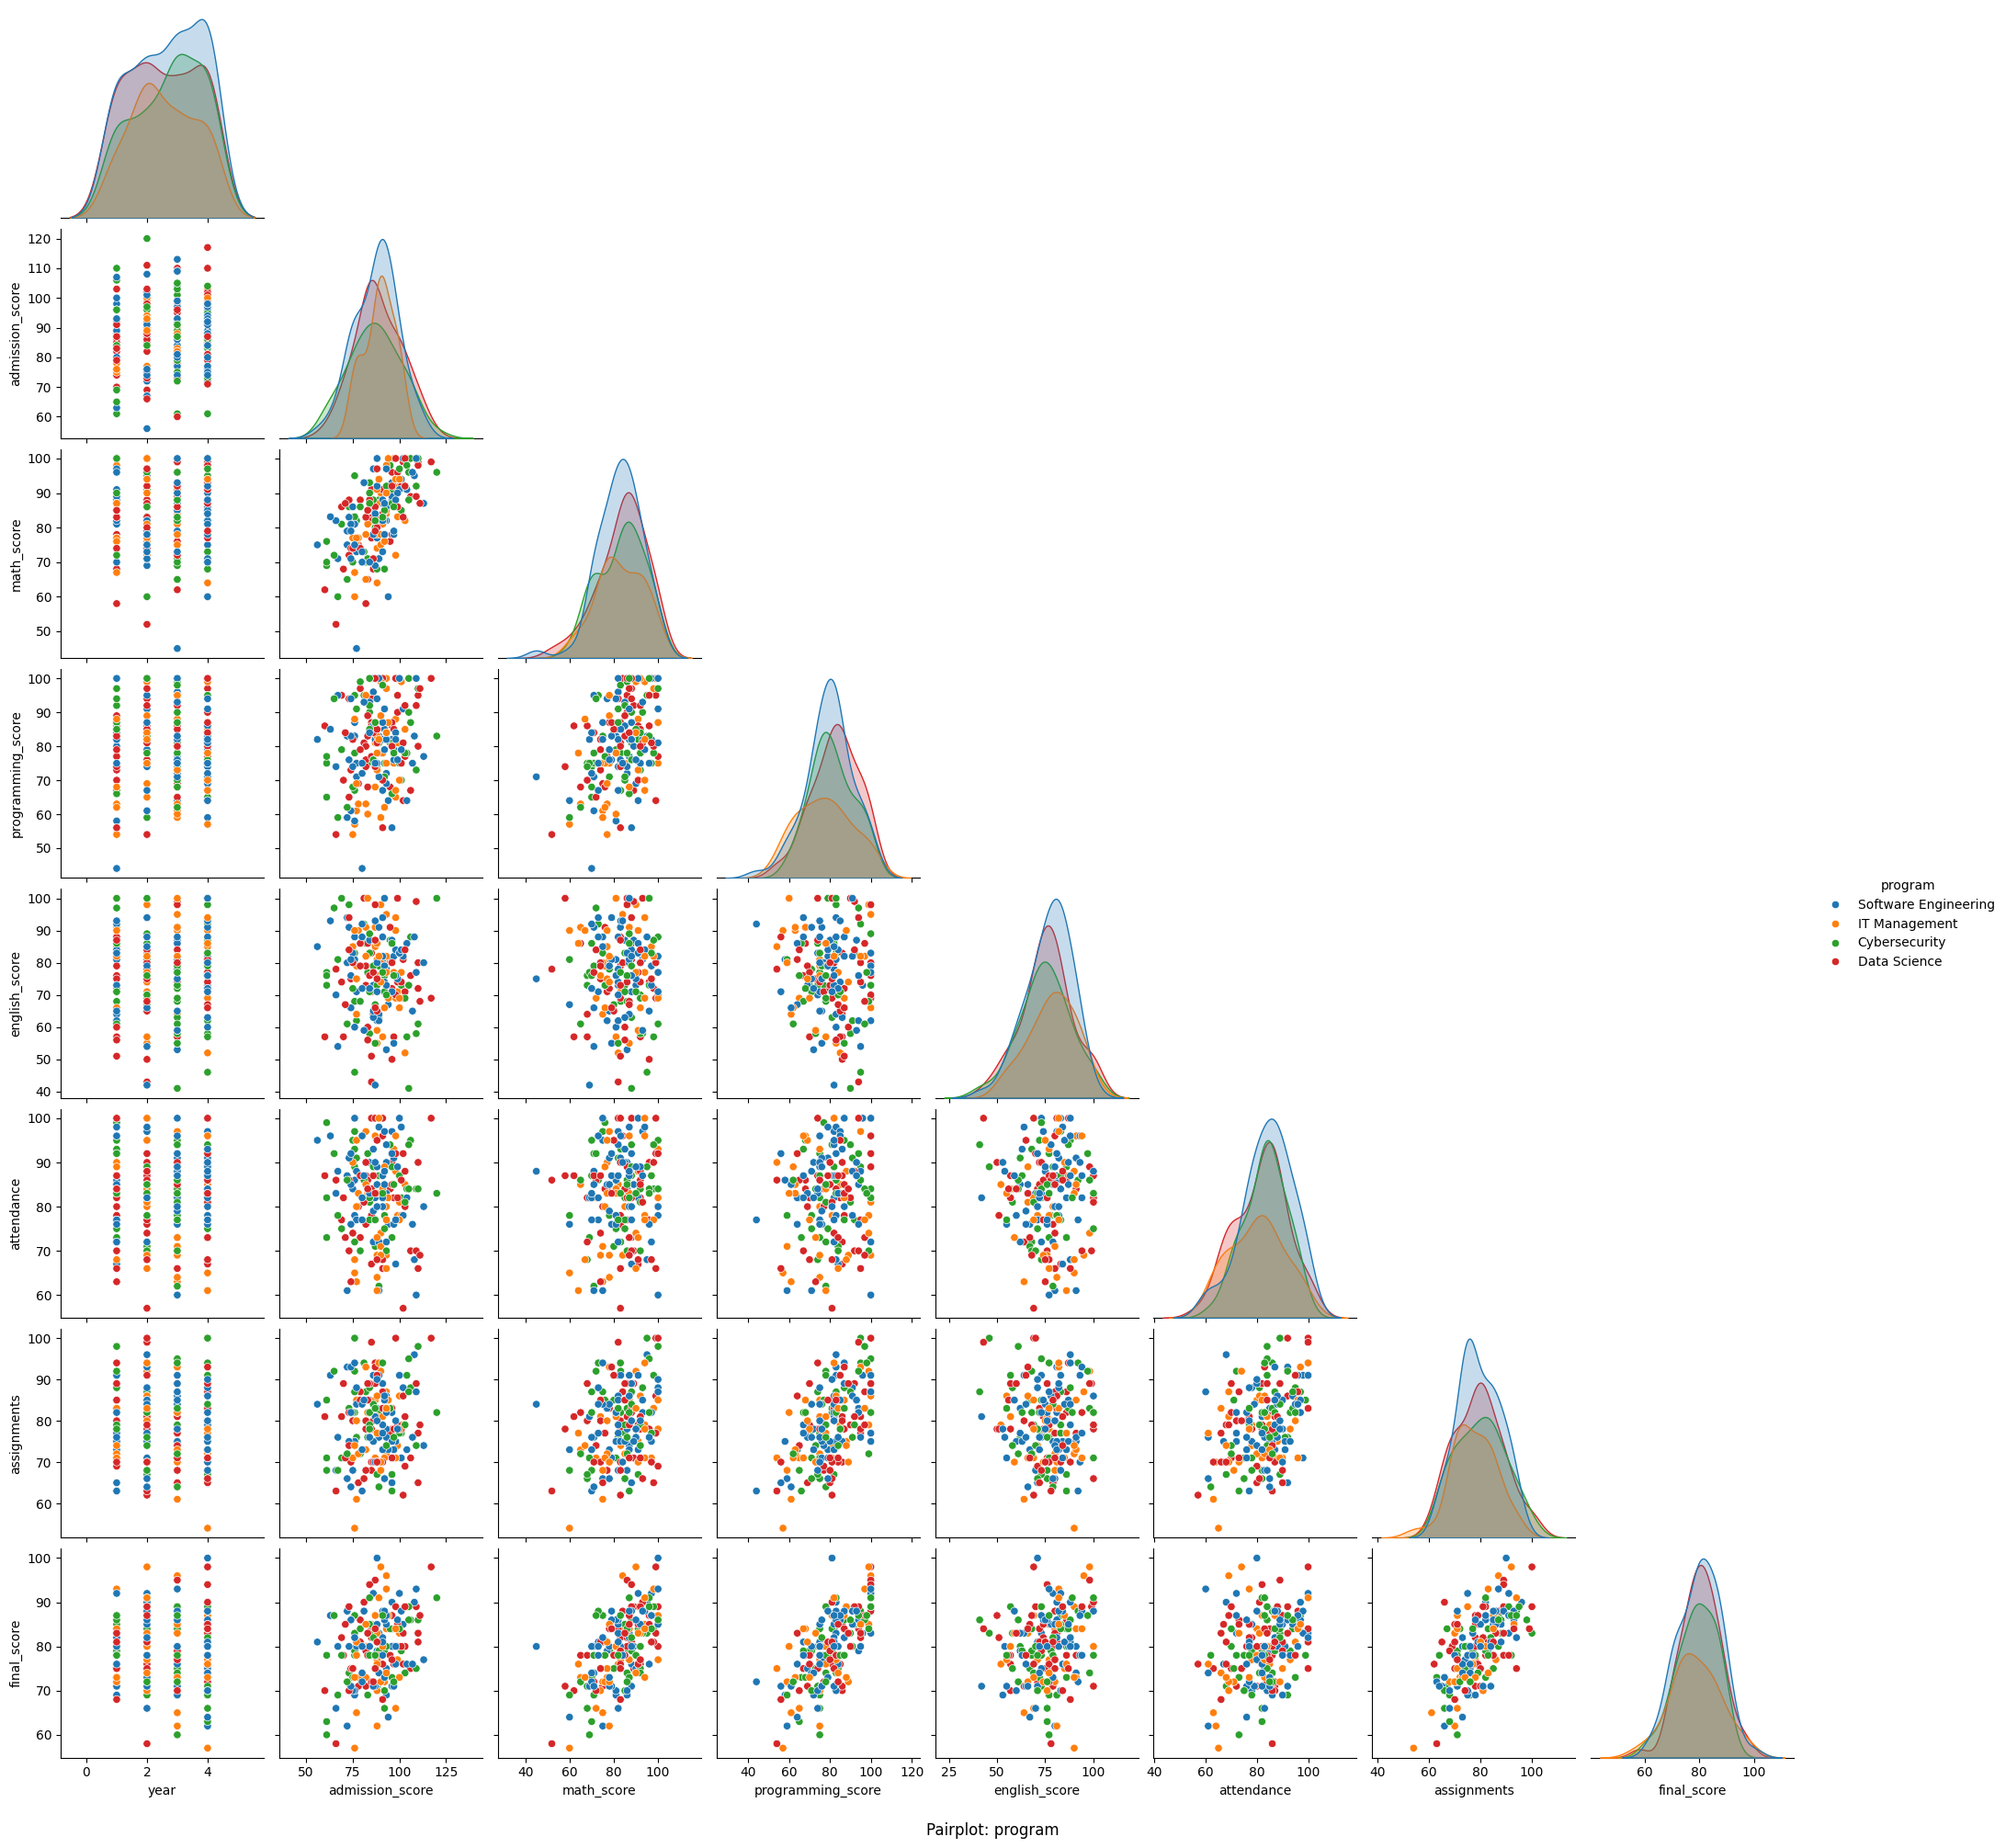

In [ ]:
# Матрица диаграмм рассеяния + KDE по диагонали
sns.pairplot(df_clean, hue="program", corner=True,
             diag_kind="kde")  # corner=True — только нижний треугольник
plt.suptitle("Pairplot: program", y=0)
plt.show()

# параметр y=1.02 задаёт вертикальное положение общего заголовка.
# Координата y задаётся относительно всей фигуры:
# - y=0 — нижняя граница;
# - y=0.5 — середина;
# - y=1.0 — верхняя граница;
# - y=1.02 — немного выше верхней границы графиков.
# The y parameter controls the vertical position of the figure title. A value of 1.02 places the title slightly above the top of the plots.